# State of the art: curve fitting, stochastic rates, deposit models, the 2024 recalibration and the open-source gap

- **Level:** 3, State of the art
- **Prerequisites:** notebooks 01 to 06 of this topic
- **Reading time:** about 55 minutes

## Objectives

By the end of this notebook you can:

- place the methods of the case (Nelson-Siegel and Svensson curves, dynamic Nelson-Siegel, Hull-White scenarios, the replicating portfolio, the deposit beta, prepayment models) in the state of the art the research found, with its sources, and say what the engine implements and what it does not;
- measure how much the choice of curve family moves the EVE of the same balance sheet;
- compare the first-order gap and duration approximations with the full revaluation and with the dynamic NII on the same three dates, and say when they disagree even in sign;
- compare three treatments of the deposits (every deposit overnight, the standard's caps, and the internal replicating portfolio) on the same flows;
- read the 2016 and the 2024 calibrations side by side, and state what is known about the open-source tools that could challenge the results;
- compare each recomputation with the committed value, naming the engine version that baked it.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import curves, eve_nii, shocks, slotting

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Data

The data is case C14, the interest rate risk in the banking book (IRRBB) of the bank that failed in March 2023, at three valuation dates, 2021-Q4, 2022-Q2 and 2022-Q4, as Contraste commits it: the FDIC call reports (FDIC BankFind financials, https://api.fdic.gov/banks/financials) and the US Treasury par curve (https://home.treasury.gov/resource-center/data-chart-center/interest-rates), public-domain sources of the licence class `mirror-allowed`. The bank is **real in aggregate and synthetic in behaviour**. Money is in USD thousands and a positive delta EVE is a loss.

- **Files read:** `data/derived/C14/vd-2021-q4.json`, `vd-2022-q2.json` and `vd-2022-q4.json` (`outputs.balance_sheet`, `curve`, `scenarios`, `behavioural_comparison`, `ladder`, `dynamic_nii`, `nmd_segments`) and `models-svb-2021-2022.json` (`fit.nmd_models`, the replicating fits). The research notes behind the state of the art are the dossiers 01 (Basel framework), 03 (Chile) and 05 (market, ALM and liquidity models) of the Contraste research.

The level 3 notebook compares, on the same data, what the case does (levels 1 and 2) with what the literature offers. The next cell loads the files and rebuilds, for each date, the net flows of the balance sheet under the behavioural and the contractual treatment (as in notebook 01).

In [2]:
# Load the three dates and the model document; rebuild the net flows of each treatment and the zero rates at the midpoints
ROOT = Path("../../..").resolve()
docs = {q: json.loads((ROOT / "data" / "derived" / "C14" / f"vd-{q.lower()}.json").read_text(encoding="utf-8")) for q in ("2021-Q4", "2022-Q2", "2022-Q4")}
fit = json.loads((ROOT / "data" / "derived" / "C14" / "models-svb-2021-2022.json").read_text(encoding="utf-8"))["fit"]
MID = slotting.bucket_grid().midpoints
LANG = "en"  # the bilingual fields of the documents are read in this language
# Names of the document's own values in this language (the identifiers of the file stay as they are)
NAME = {"behavioural": "behavioural", "contractual": "contractual", "parallel-up": "parallel up",
        "parallel-down": "parallel down", "steepener": "steepener", "flattener": "flattener",
        "short-up": "short up", "short-down": "short down", True: "yes", False: "no"}

book = {}
for q, d in docs.items():
    o = d["outputs"]
    sides = {}
    for treatment in ("behavioural", "contractual"):
        a, l = np.zeros(19), np.zeros(19)
        for item in o["balance_sheet"]["items"]:
            for row in item["cash_flows"][treatment]:
                if item["side"] == "asset":
                    a[row["bucket"] - 1] += row["amount"]
                else:
                    l[row["bucket"] - 1] -= row["amount"]
        sides[treatment] = (a, l)
    book[q] = {"flows": sides, "r0": np.array(o["curve"]["zero_rates_at_midpoints"]), "tier1": o["scenarios"][0]["outlier"]["tier1"]}
    print(q, o["valuation_date"], "| baked by riskvalidation", d["provenance"]["riskvalidation_version"], "| installed", rv.__version__, "| Tier 1", f"{book[q]['tier1']:,.0f}")

2021-Q4 2021-12-31 | baked by riskvalidation 1.0.1 | installed 1.0.1 | Tier 1 14,622,000
2022-Q2 2022-06-30 | baked by riskvalidation 1.0.1 | installed 1.0.1 | Tier 1 16,349,000
2022-Q4 2022-12-31 | baked by riskvalidation 1.0.1 | installed 1.0.1 | Tier 1 16,995,000


## Method

Each comparison below uses the same committed flows and curves as the level 2 notebooks and changes one choice at a time, so a difference in the result is attributable to that choice. There are four comparisons: (1) the curve family, (2) the first-order approximations against the full revaluation and the dynamic projection, (3) three treatments of the deposits, and (4) the 2016 and 2024 calibrations. The first three run the engine on the committed data; the fourth reads the committed scenarios. Each is introduced with the state of the art it stands for, in the next section.

## State of the art

The research (dossier 05, D.1 to D.7, and dossier 01, H) found the following families for each part of the IRRBB measurement. The right-hand column says what the engine `riskvalidation` 0.8.1 implements and what it does not, from its source at the tag.

| Part | State of the art (source) | In the engine |
|---|---|---|
| Curve fitting | Nelson and Siegel (1987, https://doi.org/10.1086/296409); Svensson (1994, https://doi.org/10.3386/w4871); dynamic Nelson-Siegel, Diebold and Li (2006, https://doi.org/10.1016/j.jeconom.2005.03.005) | `fit_nelson_siegel`, `fit_svensson`, `fit_dns_factors`, `forecast_dns_factors`; the decay 0.0609 per month is a constant |
| Interpolation | Hagan and West (2006, https://doi.org/10.1080/13504860500396032): monotone convex and other schemes change forwards materially | linear in tenor, flat outside the grid (`zero_rates_at`); no other scheme |
| Short-rate scenarios | Vasicek (1977, https://doi.org/10.1016/0304-405X(77)90016-2); Hull and White (1990, https://doi.org/10.1093/rfs/3.4.573) | `hw1f_scenarios` (Hull-White one-factor, antithetic); no Vasicek |
| Non-maturity deposits | static replicating portfolio (BCBS d368, footnote 38); contingent-claim valuation, Jarrow and van Deventer (1998, https://doi.org/10.1016/S0378-4266(97)00058-7); three-factor model, Kalkbrener and Willing (2004, https://doi.org/10.1016/S0378-4266(03)00131-6); stochastic programming, Frauendorfer and Schurle (2003, https://doi.org/10.1016/S0377-2217(02)00626-4) | `replicating_portfolio` (static, exact up to 10 tranches); none of the other three |
| Deposit beta | asymmetric pass-through, Drechsler, Savov and Schnabl (2021, https://doi.org/10.1111/jofi.13013) | `deposit_beta_passthrough` (up and down betas); the fit is the pipeline's |
| Prepayment | SMM, CPR and PSA, Fuster, Lucca and Vickery (2022); rational exercise, Stanton (1995, https://doi.org/10.1093/rfs/8.3.677); proportional hazards, Schwartz and Torous (1989, https://doi.org/10.1111/j.1540-6261.1989.tb05062.x); competing risks, Deng, Quigley and Van Order (2000, https://doi.org/10.1111/1468-0262.00110) | `smm_from_cpr`, `cpr_from_smm`, `psa_cpr`, `prepayment_logit` and `fit_prepayment_logit` (a logit on incentive and seasoning; no burnout or seasonality) |
| Shock sizes | BCBS d368 (2016) and the recalibration d578 (2024, effective 2026-01-01): 99.9th percentile of six-month changes, 2000 to 2023, rounded to 25 bp | both tables as fixtures (`shock_table`); the 2016 table is verified with a text-layer caveat, the 2024 one is the SRP31.90 Table 2 |
| The lesson of the failed bank | the Federal Reserve's review found that the bank made counterintuitive assumptions about the duration of deposits to address a breach (https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf) | `eve_with_without_behavioural` and `behavioural_change_at_breach` (notebooks 05 and 08) |
| Open-source engines | the research found no mature open-source ALM or IRRBB engine; ORE and QuantLib cover curves, Hull-White and exposure, not a bank balance sheet (dossier 05, D.6 and I.3) | not applicable; the absence is a finding of the dossier's search, **UNVERIFIED** beyond it |

Two cautions on the table. The research notes that the 2024 values were not retrieved in the market dossier (dossier 05, D.2: "UNVERIFIED") and are transcribed in the Basel dossier (dossier 01, H.3); the engine takes the second. And the Diebold-Li decay is stated in the paper as maximising the curvature loading at 30 months; the engine documents 29.446 months (notebook 04).

### Comparison 1: the curve family

Hagan and West (2006) show that the interpolation scheme moves forward rates materially; the family fitted to the market curve does the same for the present values. The cell compares four ways of getting the 19 zero rates of each date from the same 12 observed yields: the pipeline's (bootstrap and linear interpolation), the Nelson-Siegel fit, the Svensson fit and the dynamic Nelson-Siegel loadings with the fixed decay. For each the cell recomputes the EVE of the behavioural net flows and prints the difference against the pipeline's, in money and as a share of Tier 1, and the largest gap in the rates.

In [3]:
# EVE of the behavioural flows under four ways of getting the zero rates, against the pipeline's interpolated curve
families = {}
print(f"{'':8s} {'curve':26s} {'EVE':>14s} {'difference':>14s} {'of Tier 1':>12s} {'largest rate gap (bp)':>28s}")
for q, d in docs.items():
    pts = d["outputs"]["curve"]["points"]
    tenors = np.array([p["tenor_years"] for p in pts])
    zero = np.array([p["zero_rate"] for p in pts])
    ns = curves.fit_nelson_siegel(tenors, zero)
    sv = curves.fit_svensson(tenors, zero)
    factors = curves.fit_dns_factors(tenors * 12.0, zero[None, :])[0]
    rates = {
        "pipeline: bootstrap + linear": book[q]["r0"],
        "Nelson-Siegel": curves.nelson_siegel_yield(MID, ns.beta0, ns.beta1, ns.beta2, ns.tau),
        "Svensson": curves.svensson_yield(MID, sv.beta0, sv.beta1, sv.beta2, sv.beta3, sv.tau1, sv.tau2),
        "dynamic Nelson-Siegel (λ fixed)": curves.dns_yield(MID * 12.0, *factors),
    }
    a, l = book[q]["flows"]["behavioural"]
    reference = None
    for name, r in rates.items():
        value = eve_nii.eve(a - l, r, MID)
        reference = value if reference is None else reference
        families[(q, name)] = value
        print(f"{q:8s} {name:26s} {value:14,.0f} {value - reference:14,.0f} {(value - reference) / book[q]['tier1']:12.4f} {np.abs(r - book[q]['r0']).max() * 1e4:28.1f}")

         curve                                 EVE     difference    of Tier 1        largest rate gap (bp)
2021-Q4  pipeline: bootstrap + linear      8,982,670              0       0.0000                          0.0
2021-Q4  Nelson-Siegel                   8,813,494       -169,176      -0.0116                         10.2
2021-Q4  Svensson                        8,961,548        -21,122      -0.0014                         24.0
2021-Q4  dynamic Nelson-Siegel (λ fixed)      8,841,860       -140,810      -0.0096                         11.7
2022-Q2  pipeline: bootstrap + linear      7,036,780              0       0.0000                          0.0
2022-Q2  Nelson-Siegel                   7,142,430        105,650       0.0065                         46.3
2022-Q2  Svensson                        6,647,794       -388,987      -0.0238                         31.0
2022-Q2  dynamic Nelson-Siegel (λ fixed)      7,360,948        324,168       0.0198                         37.4
2022-Q4  pipel

### Comparison 2: the first-order approximations, the full revaluation and the dynamic NII

Notebook 01 gave two first-order approximations, the repricing gap for the NII and the duration gap for the equity. They are cheap, they need no scenario curve, and the literature treats them as indicators; the standard asks for the full revaluation. The cell puts them side by side for a +200 bp parallel shock, the USD size of the 2024 table, on the three dates and the two treatments of the deposits. For the equity, the first-order change is $-DGAP \cdot A \cdot \Delta y$ (scaled from the +100 bp the engine returns, since it is linear in the shift), and the full revaluation is the committed delta EVE of the parallel-up shock, loss-positive. For the NII, the gap approximation is twice the engine's value at +100 bp, and the dynamic projection is the committed one, loss-positive (a negative number is a gain).

In [4]:
# Loss from the duration gap and from the full revaluation, and NII loss from the gap and from the dynamic projection, for +200 bp
print(f"{'':8s} {'deposits':14s} {'equity: first order':>26s} {'equity: revaluation':>28s} {'NII: gap':>14s} {'NII: dynamic':>16s}")
approx = {}
for q, d in docs.items():
    o = d["outputs"]
    dynamic_up = next(s["delta_vs_base"] for s in o["dynamic_nii"]["scenarios"] if s["scenario"] == "parallel-up")
    for treatment in ("behavioural", "contractual"):
        a, l = book[q]["flows"][treatment]
        dg = eve_nii.duration_gap(a, l, book[q]["r0"], MID)
        first_order_loss = -2.0 * dg.equity_change_100bp_up
        full = next(r for r in o["behavioural_comparison"] if r["calibration"] == "2024" and r["shock"] == "parallel-up")[f"delta_eve_{treatment}"]
        gap_nii = 2.0 * eve_nii.delta_nii_gap(eve_nii.repricing_gap(a, l), MID, 100.0)
        approx[(q, treatment)] = (first_order_loss, full, gap_nii, dynamic_up)
        shown_dynamic = f"{dynamic_up:16,.0f}" if treatment == "behavioural" else f"{'-':>16s}"
        print(f"{q:8s} {NAME[treatment]:14s} {first_order_loss:26,.0f} {full:28,.0f} {gap_nii:14,.0f} {shown_dynamic}")

         deposits              equity: first order          equity: revaluation       NII: gap     NII: dynamic
2021-Q4  behavioural                     5,549,598                    4,696,830        455,806       -1,138,367
2021-Q4  contractual                    17,508,990                   15,541,007      2,471,558                -
2022-Q2  behavioural                     4,016,983                    3,389,351        398,114       -1,058,869
2022-Q2  contractual                    14,096,514                   12,611,380      2,398,976                -
2022-Q4  behavioural                     3,602,676                    3,058,469        349,294         -483,444
2022-Q4  contractual                    12,246,721                   10,983,866      2,186,939                -


### Comparison 3: three treatments of the deposits

The standard slots the stable part of the non-maturity deposits under caps; the internal practice replicates the deposit with a portfolio of rolling tranches and uses its average maturity. The cell takes the wholesale segment, the largest, and slots it three ways with the engine's `nmd_split`: every deposit overnight (the contractual reading), the standard's caps (the committed behavioural reading, 50 percent core at 4 years), and the **replicating** reading, where the whole balance sits at the average maturity of the committed replicating fit of the date (share 100 percent, no cap, `enforce_caps=False`). The rest of the balance sheet is kept as committed. For each treatment it prints the EVE and the loss under the +200 bp parallel shock with the zero floor, so the only thing that changes is the treatment of the wholesale deposits. This is a what-if on the committed flows (it omits the early redemption of term deposits, a 322,000 item, from the shocked flows), not a committed number.

In [5]:
# Slot the wholesale deposits three ways and compute the EVE and the loss under +200 bp with the zero floor
deposit = {}
print(f"{'':8s} {'treatment':22s} {'average maturity (y)':>24s} {'EVE':>14s} {'loss +200 bp':>18s} {'of Tier 1':>12s}")
for q, d in docs.items():
    o = d["outputs"]
    segment = next(s for s in o["nmd_segments"] if s["category"] == "wholesale")
    model = next(m for m in fit["nmd_models"] if m["valuation_date"] == o["valuation_date"])
    standard = slotting.nmd_split(segment["balance"], "wholesale", segment["requested_core_share"], segment["requested_core_maturity_years"])
    a, l = book[q]["flows"]["behavioural"]
    others = (a - l) + standard.flows
    treatments = {
        "contractual": slotting.nmd_split(segment["balance"], "wholesale", 0.0, 0.0),
        "standard caps": standard,
        "replicating portfolio": slotting.nmd_split(segment["balance"], "wholesale", 1.0, model["weighted_average_maturity_years"], enforce_caps=False),
    }
    shocked_rates = shocks.apply_floor(book[q]["r0"], np.full(19, 200.0), 0.0)
    for name, split in treatments.items():
        net = others - split.flows
        value = eve_nii.eve(net, book[q]["r0"], MID)
        loss = eve_nii.delta_eve(net, net, book[q]["r0"], shocked_rates, MID)
        wam = float((split.flows * MID).sum() / split.flows.sum())
        deposit[(q, name)] = (value, loss)
        print(f"{q:8s} {NAME.get(name, name):22s} {wam:24.4f} {value:14,.0f} {loss:18,.0f} {loss / book[q]['tier1']:12.4f}")

         treatment                  average maturity (y)            EVE       loss +200 bp    of Tier 1
2021-Q4  contractual                              0.0028      4,868,904         11,542,342       0.7894
2021-Q4  standard caps                            2.0014      8,982,670          4,696,651       0.3212
2021-Q4  replicating portfolio                    4.7595     15,459,666         -4,423,382      -0.3025
2022-Q2  contractual                              0.0028     -3,373,439          9,694,356       0.5930
2022-Q2  standard caps                            2.0014      7,036,780          3,389,057       0.2073
2022-Q2  replicating portfolio                    4.2049     18,465,257         -3,460,623      -0.2117
2022-Q4  contractual                              0.0028     -7,338,446          8,571,364       0.5043
2022-Q4  standard caps                            2.0014      5,257,968          3,056,308       0.1798
2022-Q4  replicating portfolio                    5.0000     22,

### Comparison 4: the 2016 and the 2024 calibrations

The recalibration of the shock sizes (d578, effective 2026-01-01) is the one change of the standard in the period. The committed scenarios hold the six shocks under both tables with the capped behavioural flows, so the effect on the EVE risk measure is a read. The cell prints, for each date, the measure, the worst shock and the ratio to Tier 1 under each calibration.

In [6]:
# The EVE risk measure, the worst shock and the ratio to Tier 1 under the 2016 and the 2024 calibrations (behavioural flows)
print(f"{'':8s} {'calibration':14s} {'parallel, short, long (bp)':>32s} {'measure':>12s} {'worst shock':>22s} {'ratio':>8s}")
for q, d in docs.items():
    for cal in ("2016", "2024"):
        b = next(s for s in d["outputs"]["scenarios"] if s["calibration"] == cal and s["nmd_assumption"] == "behavioural")
        z = b["shock_size"]
        print(f"{q:8s} {cal:14s} {z['parallel_bp']:.0f}/{z['short_bp']:.0f}/{z['long_bp']:.0f}{'':>20s} {b['eve_risk_measure']:12,.0f} {NAME[b['worst_shock']]:>22s} {b['outlier']['ratio']:8.4f}")

         calibration          parallel, short, long (bp)      measure            worst shock    ratio
2021-Q4  2016           200/300/150                        4,696,830            parallel up   0.3212
2021-Q4  2024           200/300/225                        4,980,555              steepener   0.3406
2022-Q2  2016           200/300/150                        3,389,351            parallel up   0.2073
2022-Q2  2024           200/300/225                        3,418,185              steepener   0.2091
2022-Q4  2016           200/300/150                        3,058,469            parallel up   0.1800
2022-Q4  2024           200/300/225                        3,072,781              steepener   0.1808


The last cell draws the EVE under the four curve families at the three dates (left) and the loss under +200 bp for the three treatments of the wholesale deposits (right). On the left the four families are close: the differences are a small share of Tier 1. On the right the choice of treatment moves the loss by a multiple.

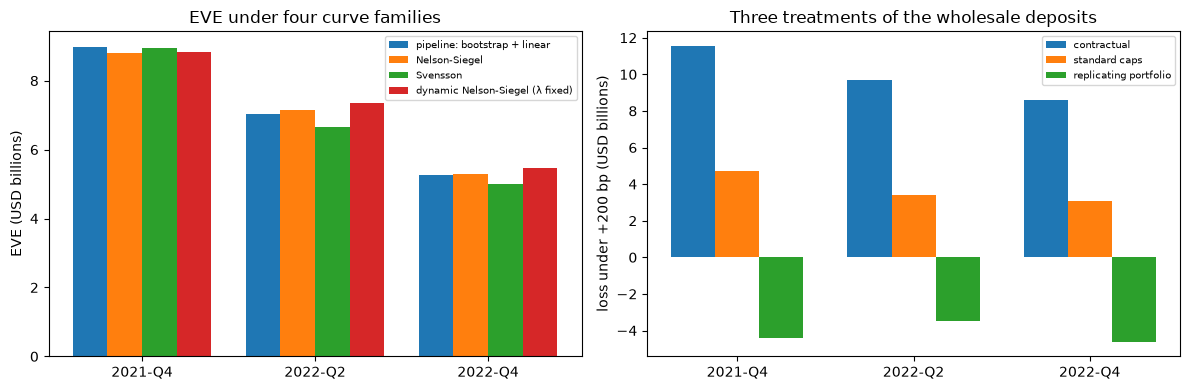

In [7]:
# Draw the EVE under four curve families and the loss under +200 bp for the three deposit treatments
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
names = list(dict.fromkeys(n for _, n in families))
for k, name in enumerate(names):
    left.bar(np.arange(3) + k * 0.2 - 0.3, [families[(q, name)] / 1e6 for q in docs], 0.2, label=name)
left.set_xticks(range(3))
left.set_xticklabels(list(docs))
left.set_ylabel("EVE (USD billions)")
left.set_title("EVE under four curve families")
left.legend(fontsize=7)
treat = list(dict.fromkeys(n for _, n in deposit))
for k, name in enumerate(treat):
    right.bar(np.arange(3) + k * 0.25 - 0.25, [deposit[(q, name)][1] / 1e6 for q in docs], 0.25, label=NAME.get(name, name))
right.set_xticks(range(3))
right.set_xticklabels(list(docs))
right.set_ylabel("loss under +200 bp (USD billions)")
right.set_title("Three treatments of the wholesale deposits")
right.legend(fontsize=7)
fig.tight_layout()
plt.show()

## Results

- **What the engine covers.** Of the families the research found, the engine implements the curve fits, Hull-White one factor, the static replicating portfolio, the deposit beta and a prepayment logit, and does not implement Vasicek, another interpolation scheme, the contingent-claim or three-factor deposit models, or stochastic programming. A validator who needs those has to bring a challenger from outside; the research found no mature open-source ALM engine to bring, a finding that stays unverified beyond the dossier's search.
- **The curve family.** On the same 12 observed yields, the four ways of getting the 19 zero rates differ from the pipeline's by up to 52 bp in a single band and move the EVE by between -389,000 and +324,000, at most 2.4 percent of Tier 1 but up to 10 percent of the EVE itself: at 2022-Q2 the four EVEs run from 6,647,794 (Svensson) to 7,360,948 (dynamic Nelson-Siegel) around the pipeline's 7,036,780. The pipeline's curve passes through every observed point and the fitted families smooth them (at 2022-Q2, with errors of 10 and 13 bp), so the comparison says how sensitive the result is to the choice, not which curve is right. The Basel measure is a ratio to Tier 1, so the choice does not change a verdict here, but it is a spread a validator should report.
- **The first-order approximations.** For +200 bp the duration gap overstates the loss of the full revaluation by 18 percent with the behavioural deposits (5,549,598 against 4,696,830 at 2021-Q4, 4,016,983 against 3,389,351 at 2022-Q2, 3,602,676 against 3,058,469 at 2022-Q4) and by 11 to 13 percent with the contractual ones: the right order of magnitude and the right sign, with a bias that is stable across the dates. The NII approximations do not agree even in sign: the gap says that a +200 bp shock costs 455,806, 398,114 and 349,294, and the dynamic projection says that it earns 1,138,367, 1,058,869 and 483,444. The difference is the deposit pass-through (the gap reprices the non-core deposits one for one, the projection gives them a beta of 0.02 to 0.26), so the sign of the NII sensitivity of this bank is a statement about its deposit beta.
- **The deposits.** At 2022-Q2 the wholesale deposits, 185 billion of the balance, give three different banks. Slotted overnight, the EVE is -3,373,439 and the +200 bp loss 9,694,356, 59 percent of Tier 1. With the standard's caps, the EVE is 7,036,780 and the loss 3,389,057, 21 percent (the committed number is 3,389,351; the 294 of difference is the early redemption of term deposits left out here). With the replicating portfolio the whole balance sits at 4.2 years, the EVE is 18,465,257 and the +200 bp shock is **a gain** of 3,460,623. The sign flips at the three dates (4.76, 4.20 and 5.00 years). This is the lever the review of the failed bank describes: a long deposit duration, fitted from the bank's own history, can make a loss disappear, and the caps of the standard are what stops it. Notebook 05 showed that the weights behind those maturities are not stable.
- **The 2024 recalibration.** Under the 2016 sizes the worst shock is the parallel-up at the three dates; under the 2024 sizes, whose long size is 225 bp instead of 150 bp, it is the steepener. The measure rises by 6.0 percent at 2021-Q4 (4,696,830 to 4,980,555), 0.9 percent at 2022-Q2 and 0.5 percent at 2022-Q4, and the ratio stays over the line of 15 percent in every case: the recalibration changes the shape that hurts most, not the verdict of this case.
- **What the notebook does not show.** That any of the alternatives is better than the pipeline's choices: there is no truth to compare against for a bank whose behaviour is synthetic. The notebook shows the size of the choices, so a validator knows where to look first: the deposit treatment, then the beta, then the curve.

## Summary

- The engine implements a part of the state of the art: the curve families, Hull-White one factor, the static replicating portfolio, the deposit beta and a prepayment logit; it does not implement Vasicek, other interpolation schemes, the contingent-claim or the three-factor deposit models, or stochastic programming.
- The curve family moves the EVE of the same flows by a small share of Tier 1; the deposit treatment moves the loss by a multiple.
- The first-order approximations give the order of magnitude of the equity change but the gap and the dynamic NII can differ even in sign, because they treat the deposit pass-through differently.
- The 2024 recalibration changes the sizes of the long end and so the worst shock of the case, from the parallel-up to the steepener, without changing the verdict of the outlier test.
- No mature open-source engine was found to challenge the results; that is a finding of the dossier's search, unverified beyond it.

**What to try next.** Replace the +200 bp of comparison 3 by the steepener of notebook 02 and see whether the order of the three deposit treatments holds. Then continue with notebook 08, the components beyond the state of the art.

## References

- Nelson, C. R. and Siegel, A. F. (1987), Parsimonious modeling of yield curves, Journal of Business 60(4). https://doi.org/10.1086/296409
- Svensson, L. E. O. (1994), Estimating and interpreting forward interest rates: Sweden 1992-1994, NBER Working Paper 4871. https://doi.org/10.3386/w4871
- Diebold, F. X. and Li, C. (2006), Forecasting the term structure of government bond yields, Journal of Econometrics 130(2). https://doi.org/10.1016/j.jeconom.2005.03.005
- Hagan, P. S. and West, G. (2006), Interpolation methods for curve construction, Applied Mathematical Finance 13(2). https://doi.org/10.1080/13504860500396032
- Vasicek, O. (1977), An equilibrium characterization of the term structure, Journal of Financial Economics 5(2). https://doi.org/10.1016/0304-405X(77)90016-2
- Hull, J. and White, A. (1990), Pricing interest-rate-derivative securities, Review of Financial Studies 3(4). https://doi.org/10.1093/rfs/3.4.573
- Jarrow, R. and van Deventer, D. (1998), The arbitrage-free valuation and hedging of demand deposits and credit card loans, Journal of Banking and Finance 22(3). https://doi.org/10.1016/S0378-4266(97)00058-7
- Kalkbrener, M. and Willing, J. (2004), Risk management of non-maturing liabilities, Journal of Banking and Finance 28(7). https://doi.org/10.1016/S0378-4266(03)00131-6
- Frauendorfer, K. and Schurle, M. (2003), Multistage stochastic programming: optimal reinvestment of non-maturing liabilities, European Journal of Operational Research 151(3). https://doi.org/10.1016/S0377-2217(02)00626-4
- Drechsler, I., Savov, A. and Schnabl, P. (2021), Banking on deposits: maturity transformation without interest rate risk, Journal of Finance 76(3). https://doi.org/10.1111/jofi.13013
- Stanton, R. (1995), Rational prepayment and the valuation of mortgage-backed securities, Review of Financial Studies 8(3). https://doi.org/10.1093/rfs/8.3.677
- Schwartz, E. S. and Torous, W. N. (1989), Prepayment and the valuation of mortgage-backed securities, Journal of Finance 44(2). https://doi.org/10.1111/j.1540-6261.1989.tb05062.x
- Deng, Y., Quigley, J. M. and Van Order, R. (2000), Mortgage terminations, heterogeneity and the exercise of mortgage options, Econometrica 68(2). https://doi.org/10.1111/1468-0262.00110
- Fuster, A., Lucca, D. and Vickery, J. (2022), Mortgage-backed securities, FRBNY Staff Report 1001. https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr1001.pdf
- BCBS, Standards: Interest rate risk in the banking book, SRP31. https://www.bis.org/basel_framework/chapter/SRP/31.htm
- BCBS (2016), d368, Standards: Interest rate risk in the banking book. https://www.bis.org/bcbs/publ/d368.htm
- BCBS (2024), d578, Recalibration of shocks for interest rate risk in the banking book. https://www.bis.org/publications/202407-standards-recalibration-shocks-interest-rate-risk-banking-book.pdf
- Board of Governors of the Federal Reserve System (2023), Review of the Federal Reserve's Supervision and Regulation of Silicon Valley Bank. https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf
- Dossiers 01, 03 and 05 of the Contraste research (Basel framework; Chile; market, ALM and liquidity models).